# 1. Descriptives: where the outlets are

**Question.** Before any model: how many PCSO lotto outlets are there per person in poorer and richer places, nationally and inside the three cities of RQ3: Metro Manila (the National Capital Region, NCR), Metro Cebu and Metro Davao (notebook 3 defines them)?

**Data.** The phase 2 tables: `data/derived/tiles.csv` (one row per 2.4 km Relative Wealth Index tile with people, 40,737) and `data/derived/barangays.csv` (one row per barangay with people and an RWI value, 41,923).
Outlets are those placed in a barangay by GPS or address (7,271 on tiles, 7,282 on barangays).

**Method.** Each scope is split into five wealth quintiles by RWI, weighted by population, so each quintile holds a fifth of the scope's people.
Each city's quintiles split that city's own people, so they compare its poorer and richer parts with each other, not with the country.
These tables adjust for nothing: they describe where outlets are, and the models in notebooks 2 and 3 add the controls.

In [1]:
import sys
from pathlib import Path

# The notebooks import their logic from src/: the shared helpers and the analysis functions.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "shared").is_dir())
for folder in ("src/shared", "src/03_analyse"):
    sys.path.insert(0, str(ROOT / folder))

import pandas as pd
from IPython.display import Image

from analysis_samples import RWI_SD, TABLES

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

import charts
import outlet_rates
import pcso_cy2023

## Outlets per 100,000 people by wealth quintile

In [2]:
q = outlet_rates.quintile_rates()
q.to_csv(TABLES / "quintile_rates.csv", index=False, float_format="%.6g")

q.pivot_table(index=["scope", "unit"], columns="quintile", values="outlets_per_100k", sort=False).round(1)

quintile                 1     2     3     4     5   All
scope       unit                                        
National    tile       0.4   2.3   6.7  10.4  12.7   6.5
            barangay   0.4   2.4   6.4  10.5  12.6   6.5
NCR         tile      14.4  13.9  13.8  13.7  13.2  13.8
            barangay  15.2  12.5  14.9  14.0  14.1  14.1
Metro Cebu  tile       1.0   5.9   8.1  15.4   7.0   7.5
            barangay   1.4   5.2   9.5  12.8   8.4   7.5
Metro Davao tile       0.0   1.6   4.9   7.8  13.0   5.5
            barangay   0.1   2.2   4.6   7.5  12.7   5.5

**Reading.** Nationally the outlet rate climbs steeply with wealth: about 0.4 outlets per 100,000 people in the poorest fifth of tiles, 12.7 in the richest, on both tiles and barangays.
Inside NCR there is no such climb: every quintile sits between about 12.5 and 15.2, close to NCR's overall 14.1, and the poorest fifth of barangays is if anything slightly above the rest.
Metro Cebu climbs from 1.4 in its poorest fifth of barangays to 12.8 in the fourth, then falls back to 8.4 in the richest.
Metro Davao climbs all the way, from 0.1 (one outlet among 687,000 people) to 12.7, much like the national gradient.
The poorest fifths of Cebu and Davao are also their least urban and least commercial parts: 0.8 shops per 1,000 people in both, against 5 to 8 in their two richest fifths, and in Davao only 38% of the poorest fifth's people live in an urban cell.

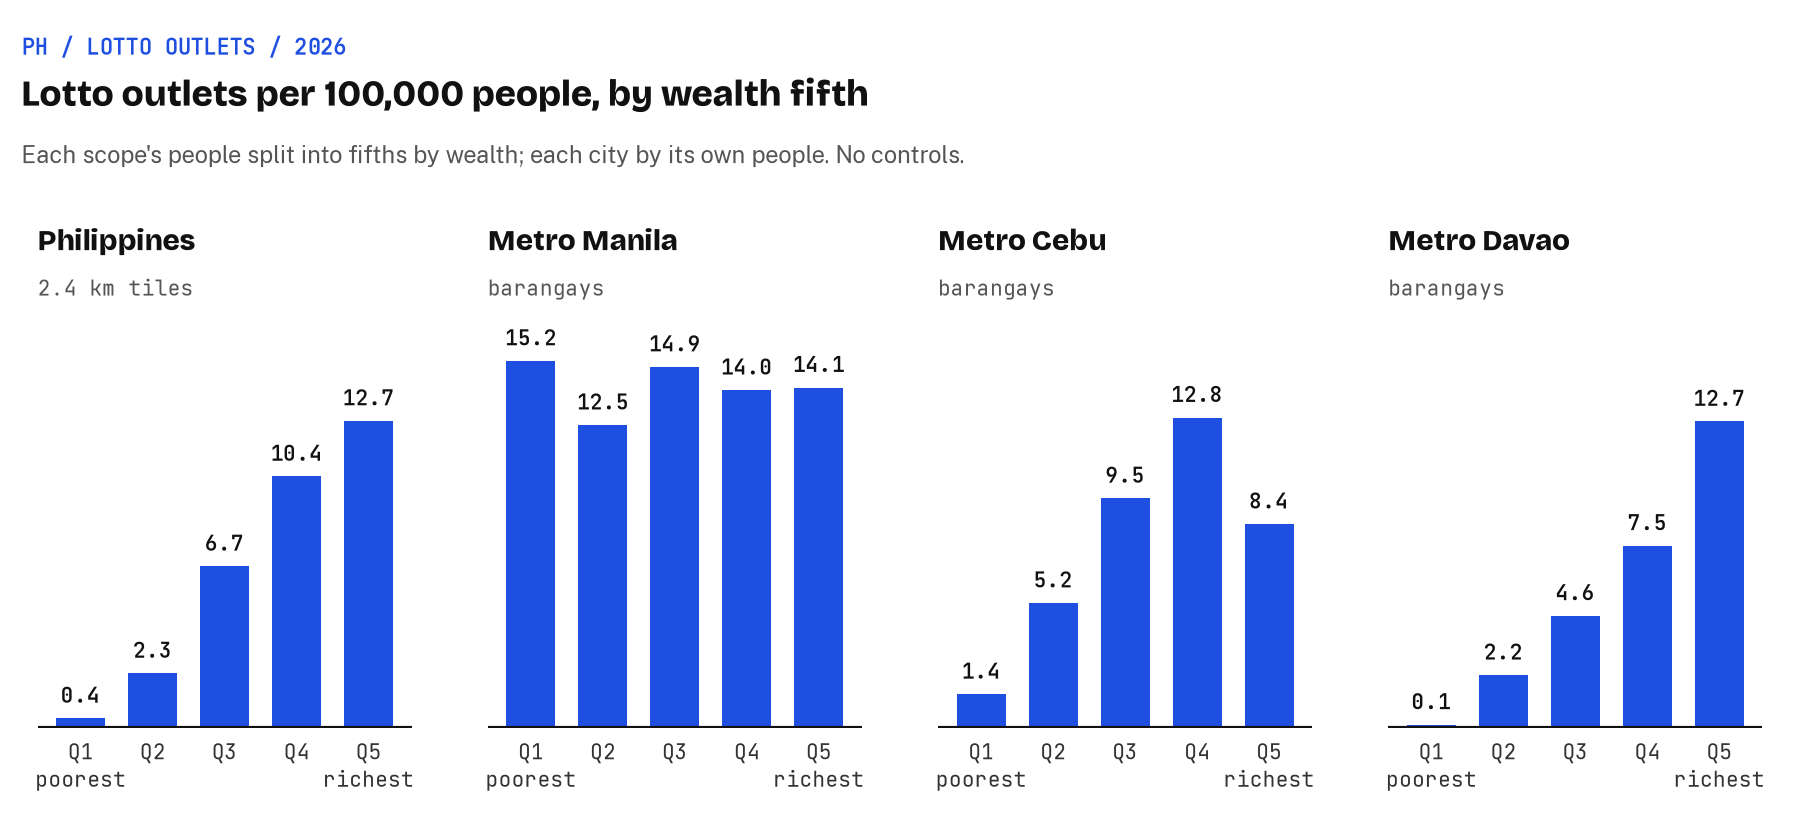

In [3]:
Image(charts.quintile_chart(q), width=720)

## How many places have no outlet at all

In [4]:
q.pivot_table(index=["scope", "unit"], columns="quintile", values="share_units_no_outlet", sort=False).round(3)

quintile                  1      2      3      4      5    All
scope       unit                                              
National    tile      0.997  0.958  0.748  0.448  0.148  0.943
            barangay  0.996  0.960  0.861  0.698  0.630  0.907
NCR         tile      0.200  0.000  0.000  0.000  0.000  0.058
            barangay  0.610  0.557  0.560  0.545  0.679  0.599
Metro Cebu  tile      0.980  0.517  0.111  0.100  0.077  0.751
            barangay  0.962  0.654  0.345  0.255  0.345  0.655
Metro Davao tile      1.000  0.944  0.612  0.333  0.111  0.930
            barangay  0.996  0.923  0.600  0.489  0.362  0.836

**Reading.** Outlets are rare in the national grid: 94% of populated tiles and 91% of barangays have none, and almost every tile in the poorest quintile (99.7%) has none.
In NCR 60% of barangays have no outlet, much the same in every quintile, while only 7 of its 121 tiles lack one; a 2.4 km tile is too coarse to tell NCR's neighbourhoods apart, which is why NCR is studied by barangay.
In Metro Cebu and Metro Davao the poorest fifth of barangays almost never has an outlet (96% and 99.6% have none), against a quarter to a third of Metro Cebu's richer three fifths and a third to three fifths of Metro Davao's.
Their tiles are sparse too: 54 of Metro Cebu's 217 tiles and 64 of Metro Davao's 913 have an outlet.

## Distributions

In [5]:
d = outlet_rates.distribution()
d.to_csv(TABLES / "distribution.csv", index=False, float_format="%.6g")
d[d.variable.isin(["outlets", "pop", "outlets_per_100k"])].round(2)

,scope,unit,variable,units,mean,sd,min,p25,median,p75,p90,p99,max,share_zero
0,National,tile,outlets,40737,0.18,1.42,0.0,0.00,0.00,0.00,0.00,4.00,49.00,0.94
1,National,tile,pop,40737,2749.63,9605.40,0.1,378.30,986.40,2237.20,4829.28,33791.51,394716.90,0.00
2,National,tile,outlets_per_100k,40737,1.78,26.21,0.0,0.00,0.00,0.00,0.00,34.43,2722.32,0.94
5,National,barangay,outlets,41923,0.17,0.89,0.0,0.00,0.00,0.00,0.00,3.00,49.00,0.91
6,National,barangay,pop,41923,2687.28,5876.14,1.0,797.00,1427.00,2623.00,4967.00,23746.42,266925.00,0.00
7,National,barangay,outlets_per_100k,41923,7.77,95.62,0.0,0.00,0.00,0.00,0.00,145.94,8823.53,0.91
10,NCR,barangay,outlets,1711,1.16,2.63,0.0,0.00,0.00,1.00,3.00,13.00,28.00,0.60
11,NCR,barangay,pop,1711,8191.81,18453.21,34.0,1119.50,2060.00,5122.00,21909.00,87243.40,266925.00,0.00
12,NCR,barangay,outlets_per_100k,1711,21.72,51.16,0.0,0.00,0.00,20.57,66.09,247.55,775.19,0.60
15,NCR,tile,outlets,121,16.22,11.88,0.0,6.00,15.00,24.00,34.00,43.60,49.00,0.06


**Reading.** Counts are small and skewed: the median tile and barangay have no outlet, and a few dense urban units hold dozens.
That skew, and the many zeros, are why the models use a negative binomial count model with a population offset rather than a regression on rates.

## Check: the map against PCSO's CY2023 agent count

PCSO's own annual report gives the number of lotto agents at the end of 2023 by sales area.
pcso.gov.ph refuses scripted downloads (HTTP 403), so the CY2023 figures below come from a search index and are marked unverified; the `cy2023_agents_from_pdf` column is left for a person to fill from the PDF.

In [6]:
pcso = pcso_cy2023.comparison_table()
pcso.to_csv(TABLES / "pcso_cy2023_check.csv", index=False)
pcso[["pcso_area", "map_outlets", "map_outlets_placed_in_barangay", "cy2023_agents_search_index", "map_vs_cy2023", "status"]]

,pcso_area,map_outlets,map_outlets_placed_in_barangay,cy2023_agents_search_index,map_vs_cy2023,status
0,National Capital Region,1998,1976,1850,1.080,"manual: unverified, read the figure off the PDF"
1,Northern and Central Luzon,1282,1265,1111,1.154,"manual: unverified, read the figure off the PDF"
2,Southern Luzon and Bicol Region,1933,1879,1695,1.140,"manual: unverified, read the figure off the PDF"
3,Visayas,1385,1340,1124,1.232,"manual: unverified, read the figure off the PDF"
4,Mindanao,845,824,636,1.329,"manual: unverified, read the figure off the PDF"
5,Total,7443,7284,6416,1.160,"manual: unverified, read the figure off the PDF"


**Reading.** The map lists more outlets than the CY2023 count in every area (1.16 times overall, 1.08 in NCR, 1.33 in Mindanao), so it reads as a later and fuller list rather than a partial one.
The comparison stays manual until the PDF figures are checked.